In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             f1_score, precision_recall_curve, average_precision_score)

In [2]:
DATA_DIR = Path("../logistic_regression_modeling/final_data")

df = pd.read_csv(DATA_DIR / "cleaned_2019.csv")
df = df[[i for i in df.columns if 'original' not in i]]
df = df[[i for i in df.columns if 'qa' not in i]]
df = df[[i for i in df.columns if 'income' not in i]]
df = df.iloc[:, :-4]
df = df.drop(columns=['fd_label', 'label_status', 'label_reason'])

print(df.shape)
df.head()

(72531, 32)


,tract_id,State,County,meta_dataset_version,meta_population_census_year,meta_tract_vintage,clean__Urban,clean__population_total,clean__occupied_housing_units_total,clean__GroupQuartersFlag,...,clean__PovertyRate,clean__MedianFamilyIncome,clean__TractLOWI,clean__TractHUNV,clean__TractSNAP,clean__LATracts_half,clean__LATracts1,clean__LATractsVehicle_20,clean__low_access_population_1_20,FD_2
0,1001020100,Alabama,Autauga County,2019,2010,2010,1.0,1912.0,693.0,0.0,...,11.3,81250.0,455.0,6.0,102.0,1.0,1.0,0.0,1896.0,1
1,1001020200,Alabama,Autauga County,2019,2010,2010,1.0,2170.0,743.0,0.0,...,17.9,49000.0,802.0,89.0,156.0,1.0,1.0,0.0,1261.0,1
2,1001020300,Alabama,Autauga County,2019,2010,2010,1.0,3373.0,1256.0,0.0,...,15.0,62609.0,1306.0,99.0,172.0,1.0,1.0,0.0,1552.0,1
3,1001020400,Alabama,Autauga County,2019,2010,2010,1.0,4386.0,1722.0,0.0,...,2.8,70607.0,922.0,21.0,98.0,1.0,1.0,0.0,1363.0,1
4,1001020500,Alabama,Autauga County,2019,2010,2010,1.0,10766.0,4082.0,0.0,...,15.2,96334.0,2242.0,230.0,339.0,1.0,1.0,1.0,2643.0,1


In [3]:
TARGET = "FD_2"

ID_COLS = ["tract_id", "State", "County", "meta_dataset_version",
           "meta_population_census_year", "meta_tract_vintage"]

LEAKAGE_COLS = ["clean__low_access_population_1_20",
                "clean__LATracts_half",
                "clean__LATracts1"]

# The 10 features in the final logistic regression model (model2 / full_model)
LR_FEATURES = ["clean__occupied_housing_units_total", "clean__NUMGQTRS",
               "clean__PovertyRate", "clean__MedianFamilyIncome", "clean__TractLOWI",
               "clean__TractKids", "clean__TractHispanic", "clean__TractHUNV",
               "clean__TractSNAP", "clean__LATractsVehicle_20"]

USE_LR_FEATURES = False

if USE_LR_FEATURES:
    FEATURES = LR_FEATURES
else:
    FEATURES = [c for c in df.columns if c not in ID_COLS + LEAKAGE_COLS + [TARGET]]

print(f"{len(FEATURES)} features:")
FEATURES

22 features:


['clean__Urban',
 'clean__population_total',
 'clean__occupied_housing_units_total',
 'clean__GroupQuartersFlag',
 'clean__NUMGQTRS',
 'clean__PCTGQTRS',
 'clean__TractKids',
 'clean__TractSeniors',
 'clean__TractWhite',
 'clean__TractBlack',
 'clean__TractAsian',
 'clean__TractNHOPI',
 'clean__TractAIAN',
 'clean__TractOMultir',
 'clean__TractHispanic',
 'clean__LowIncomeTracts',
 'clean__PovertyRate',
 'clean__MedianFamilyIncome',
 'clean__TractLOWI',
 'clean__TractHUNV',
 'clean__TractSNAP',
 'clean__LATractsVehicle_20']

In [4]:
df[TARGET].value_counts(normalize=True)

FD_2
0    0.659332
1    0.340668
Name: proportion, dtype: float64

In [5]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (58024, 22)  Test: (14507, 22)


In [6]:
pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(random_state=42, n_jobs=-1)),
])

In [7]:
baseline = clone(pipeline).fit(X_train, y_train)

train_ap = average_precision_score(y_train, baseline.predict_proba(X_train)[:, 1])
test_ap  = average_precision_score(y_test,  baseline.predict_proba(X_test)[:, 1])
print(f"Baseline train AP: {train_ap:.3f}")
print(f"Baseline test AP:  {test_ap:.3f}")

Baseline train AP: 1.000
Baseline test AP:  0.803


In [8]:
param_dist = {
    "rf__n_estimators": [200, 300, 500],
    "rf__max_depth": [None, 10, 15, 20, 30],
    "rf__min_samples_leaf": [1, 2, 5, 10],
    "rf__max_features": ["sqrt", "log2", 0.5],
    "rf__class_weight": [None, "balanced"],
}

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring="average_precision",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print(f"Best cross-validated AP: {search.best_score_:.3f}")

best_model = search.best_estimator_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best settings: {'rf__n_estimators': 200, 'rf__min_samples_leaf': 10, 'rf__max_features': 0.5, 'rf__max_depth': 15, 'rf__class_weight': 'balanced'}
Best cross-validated AP: 0.807


In [9]:
cv_probs = cross_val_predict(best_model, X_train, y_train, cv=3,
                             method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.05, 0.90, 0.05)
thresh_table = pd.DataFrame({
    "threshold": thresholds.round(2),
    "accuracy": [accuracy_score(y_train, (cv_probs >= t).astype(int)) for t in thresholds],
    "f1":       [f1_score(y_train, (cv_probs >= t).astype(int)) for t in thresholds],
})

best_threshold = float(thresh_table.loc[thresh_table["accuracy"].idxmax(), "threshold"])
print("Chosen threshold (max accuracy):", best_threshold)
thresh_table

Chosen threshold (max accuracy): 0.6


,threshold,accuracy,f1
0,0.05,0.644509,0.657023
1,0.10,0.671601,0.674112
2,0.15,0.690904,0.686577
3,0.20,0.708931,0.698341
4,0.25,0.726492,0.709298
5,0.30,0.743934,0.720662
6,0.35,0.760203,0.730954
7,0.40,0.775696,0.739736
8,0.45,0.789432,0.746441
9,0.50,0.801599,0.750477


In [10]:
test_probs = best_model.predict_proba(X_test)[:, 1]

testData = df.loc[X_test.index].copy()
testData["pred_prob"] = test_probs
testData["pred_class"] = (test_probs >= best_threshold).astype(int)

print("Accuracy :", accuracy_score(y_test, testData["pred_class"]))
print(confusion_matrix(y_test, testData["pred_class"]))  # rows = actual, cols = predicted
print()
print(classification_report(y_test, testData["pred_class"], digits=3))

Accuracy : 0.8181567519128696
[[8044 1521]
 [1117 3825]]

              precision    recall  f1-score   support

           0      0.878     0.841     0.859      9565
           1      0.715     0.774     0.744      4942

    accuracy                          0.818     14507
   macro avg      0.797     0.807     0.801     14507
weighted avg      0.823     0.818     0.820     14507



In [11]:
testData["risk"] = pd.cut(
    testData["pred_prob"],
    bins=[0, 0.33, 0.67, 1],
    labels=["low-risk", "medium-risk", "high-risk"],
    include_lowest=True,
)
print(testData["risk"].value_counts())

risk
low-risk       6453
high-risk      4341
medium-risk    3713
Name: count, dtype: int64


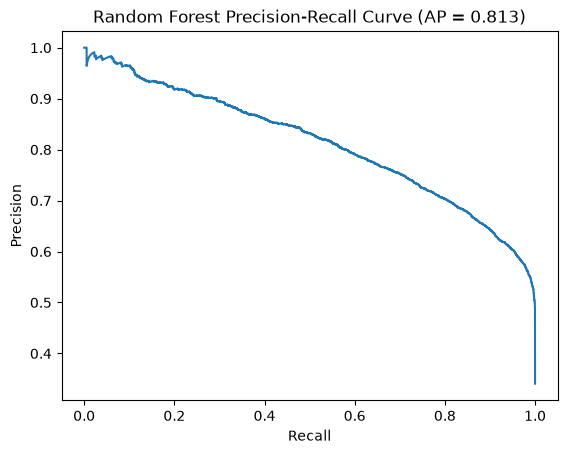

In [15]:
precision_test, recall_test, _ = precision_recall_curve(y_test, test_probs)
ap_test = average_precision_score(y_test, test_probs)

plt.plot(recall_test, precision_test)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Random Forest Precision-Recall Curve (AP = {ap_test:.3f})")
plt.show()

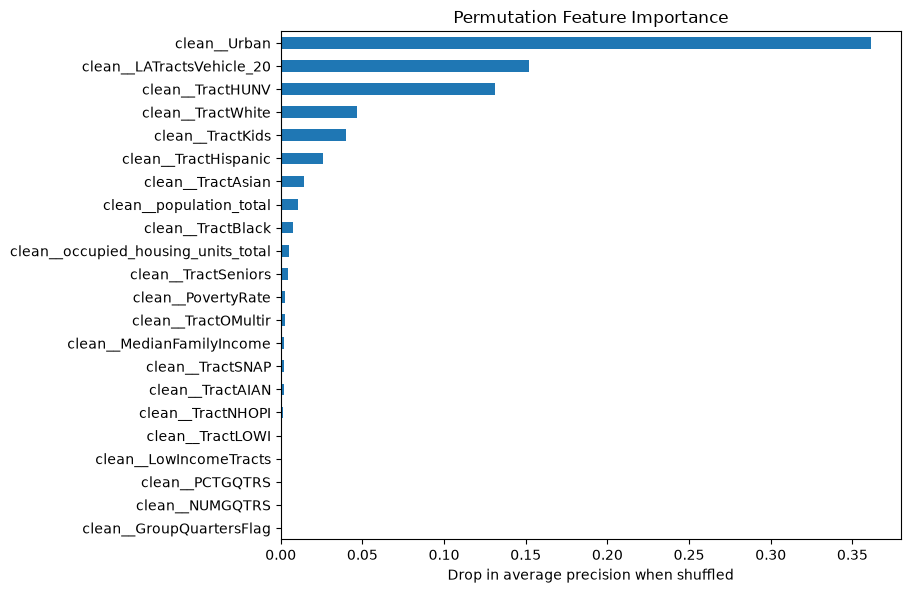

clean__Urban                           0.361491
clean__LATractsVehicle_20              0.151882
clean__TractHUNV                       0.130941
clean__TractWhite                      0.046829
clean__TractKids                       0.039956
clean__TractHispanic                   0.026050
clean__TractAsian                      0.014146
clean__population_total                0.010552
clean__TractBlack                      0.007802
clean__occupied_housing_units_total    0.005311
clean__TractSeniors                    0.004713
clean__PovertyRate                     0.002624
clean__TractOMultir                    0.002469
clean__MedianFamilyIncome              0.002139
clean__TractSNAP                       0.002135
clean__TractAIAN                       0.001706
clean__TractNHOPI                      0.001386
clean__TractLOWI                       0.001042
clean__LowIncomeTracts                 0.000544
clean__PCTGQTRS                        0.000521
clean__NUMGQTRS                        0

In [16]:
sample = X_test.sample(n=min(5000, len(X_test)), random_state=42)

imp = permutation_importance(
    best_model, sample, y_test.loc[sample.index],
    scoring="average_precision", n_repeats=5, random_state=42, n_jobs=-1,
)

importance = (pd.Series(imp.importances_mean, index=FEATURES)
                .sort_values(ascending=True))

importance.plot.barh(figsize=(8, max(4, len(FEATURES) * 0.3)))
plt.xlabel("Drop in average precision when shuffled")
plt.title("Permutation Feature Importance")
plt.show()

importance.sort_values(ascending=False)

In [17]:
final_model = clone(best_model).fit(X, y)

bundle = {
    "model": final_model,
    "features": FEATURES,
    "threshold": best_threshold,
    "best_params": search.best_params_,
}

with open("rf_model.pkl", "wb") as f:
    pickle.dump(bundle, f)

size_mb = Path("rf_model.pkl").stat().st_size / 1e6
print(f"Saved rf_model.pkl ({size_mb:.1f} MB)")

Saved rf_model.pkl (47.6 MB)
